In [2]:
import pandas as pd

df = pd.read_csv("train_data.csv")

df.head()

,subtaskID,datapointID,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
0,2,1,18.845863,15.432435,-4.888494,-11.196174,1.408862,-17.684394,3.231677,-1.476026,-4.660365,-15.947031
1,2,2,-4.746868,-5.971201,4.346016,-6.677494,1.910919,7.616225,-0.325792,-8.837899,-10.356530,-4.331975
2,2,3,2.908971,-19.955318,-11.212437,9.294100,-1.321366,-5.237313,-13.585740,-10.797363,-20.217986,-1.012807
3,2,4,-12.374266,1.094085,13.286408,3.131845,-6.065034,4.559042,-4.590903,-6.946004,-11.543627,-17.518288
4,2,5,3.261330,-12.511136,9.240270,-1.849021,-5.227230,10.490092,-7.043437,-14.084613,-15.566292,6.060100


In [7]:
df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": [1],
    "answer": 0
})

df_1

,subtaskID,datapointID,answer
0,1,1,0


In [85]:
features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10']
X = df[features]
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=features)

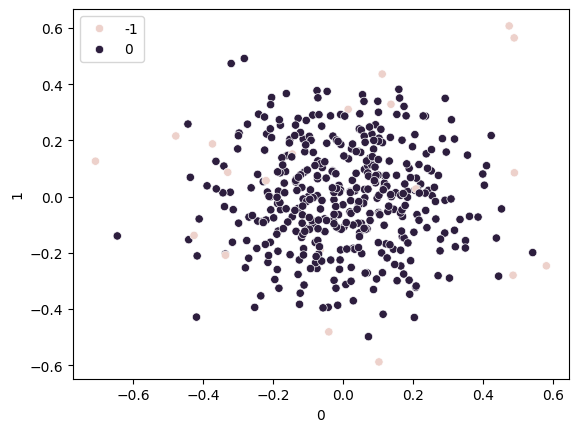

In [106]:
#zice ca sunt toate parte dintr un subset cu distanta mica intre ele (cred?)
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns

decom = PCA(n_components=2, random_state=42)
X_red = pd.DataFrame(decom.fit_transform(X))

model = DBSCAN(eps=0.511, min_samples=20)
labels = model.fit_predict(X)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [107]:
pd.Series(labels).value_counts()

 0    400
-1     20
Name: count, dtype: int64

In [108]:
labels = pd.Series(labels).map({-1: 1, 0: 0})

In [109]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": df.datapointID,
    "answer": labels
})

df_2.head()

,subtaskID,datapointID,answer
0,2,1,0
1,2,2,0
2,2,3,0
3,2,4,0
4,2,5,0


In [114]:
df_2.answer.value_counts()

answer
0    400
1     20
Name: count, dtype: int64

In [115]:
submission = pd.concat([df_1, df_2])

submission

,subtaskID,datapointID,answer
0,1,1,0
0,2,1,0
1,2,2,0
2,2,3,0
3,2,4,0
...,...,...,...
415,2,416,0
416,2,417,0
417,2,418,0
418,2,419,0


In [116]:
submission.to_csv("submission.csv", index=False)